# 📘 통계 실습: 다양한 가설검정 (5-6장)

| 문제 | 주제 | 검정 방법 | 난이도 |
|---|---|---|---|
| 1 | 게임 뽑기 확률 | 이항검정 | 하 |
| 2 | 과자 중량 | 일표본 t-검정 | 하 |
| 3 | 학습 방식 비교 | 이표본 t-검정 (+ 가정 검정, 순열검정) | 중 |
| 4 | 연령대와 장르 | 카이제곱 독립성 검정 | 중 |
| 5 | 비료 3종 비교 | 일원분산분석 + Tukey 사후검정 | 상 |

> **공통 흐름:** ① 가설 세우기 → ② 검정 실행 → ③ p-값과 유의수준 비교 → ④ 시뮬레이션으로 p-값 눈으로 확인 → ⑤ 해석


In [1]:
# ⚙️ 환경 준비: 라이브러리 불러오기 + 한글 폰트 + 시드 고정
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# 스타일을 먼저 적용한 뒤 한글 폰트를 지정해야 글꼴이 덮어써지지 않습니다.
sns.set_style("whitegrid")
system = platform.system()
if system == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
elif system == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
else:
    plt.rcParams["font.family"] = "NanumGothic"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.figsize"] = (10, 5)

print("준비 완료!")

준비 완료!


---
## 문제 1. 게임 아이템 뽑기 확률, 정말 10%일까?

### 📖 개념: 이항검정 (Binomial Test)
- **언제 쓰나:** 성공/실패 두 결과가 나오는 시행을 여러 번 했을 때, 성공률이 기준값 p₀와 같은지 검정
- **p-값의 뜻:** 개발사 주장(p₀ = 10%)이 참이라고 가정했을 때, 관찰된 결과 이하가 나올 확률
- **단측 vs 양측:** "10%보다 낮다"처럼 방향을 미리 정했으면 단측검정(`alternative="less"`)을 씀


In [2]:
# [문제 1] 게임 아이템 뽑기 확률
n_draw = 200          # 뽑은 횟수
x_obs = 12            # 성공 횟수
p0 = 0.10             # 개발사 주장 확률 (H0의 p)

print(f"관찰 성공률: {x_obs / n_draw:.1%} (기대 10%)")

관찰 성공률: 6.0% (기대 10%)


In [3]:
# [문제 1] Q1·Q2. 이항검정 (단측: 확률이 10%보다 낮은가?)
# H0: p = 0.10  /  H1: p < 0.10
# alternative='less' → "10%보다 작다"를 검정하는 단측검정
res = stats.binomtest(k=x_obs, n=n_draw, p=p0, alternative="less")
p_value = res.pvalue

print(f"성공 횟수 k = {x_obs}, 시행 횟수 n = {n_draw}")
print(f"p-value (단측) = {p_value:.4f}")

성공 횟수 k = 12, 시행 횟수 n = 200
p-value (단측) = 0.0320


In [4]:
# [문제 1] Q3. 유의수준 0.05로 결론 내리기
alpha = 0.05   # 유의수준 (1종 오류를 허용하는 최대 비율)

if p_value < alpha:
    print(f"p({p_value:.4f}) < α({alpha}) → H0 기각: 실제 확률은 10%보다 낮다고 볼 수 있음")
else:
    print(f"p({p_value:.4f}) ≥ α({alpha}) → H0 기각 못함: 10%라는 주장을 반박할 근거 부족")

p(0.0320) < α(0.05) → H0 기각: 실제 확률은 10%보다 낮다고 볼 수 있음


In [5]:
# [문제 1] Q4. "진짜 확률이 10%라면" 200번 뽑기의 성공 횟수를 10,000번 시뮬레이션
np.random.seed(42)                                   # 재현성: 난수 고정
sim_counts = np.random.binomial(n=n_draw, p=p0, size=10_000)   # 10,000번의 가상 실험 결과

# 시뮬레이션 기반 p-value: 가상 결과 중 12회 이하가 나온 비율
sim_p = np.mean(sim_counts <= x_obs)
print(f"시뮬레이션 p-value (성공 ≤ 12 비율): {sim_p:.4f}")
print(f"이항검정 p-value                  : {p_value:.4f}")

시뮬레이션 p-value (성공 ≤ 12 비율): 0.0313
이항검정 p-value                  : 0.0320


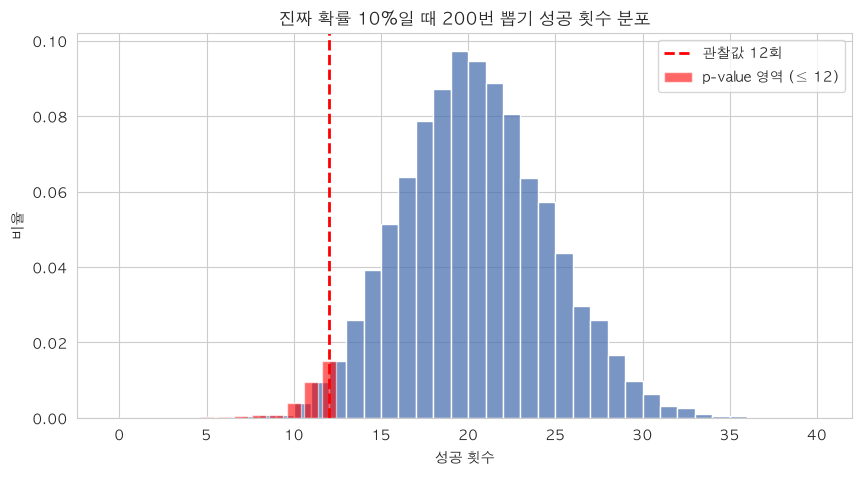

In [6]:
# [문제 1] Q5. 시뮬레이션 분포를 히스토그램으로 그리고, 관찰값(12)을 표시
plt.figure(figsize=(10, 5))
sns.histplot(sim_counts, bins=range(0, 41), color="#4C72B0", stat="probability")

# 관찰값 12 위치에 세로선 표시
plt.axvline(x_obs, color="red", linestyle="--", linewidth=2, label=f"관찰값 {x_obs}회")

# 관찰값 이하 영역(p-value에 해당)을 빨간색으로 칠하기
left_bins = np.arange(0, x_obs + 1)
plt.bar(left_bins, [np.mean(sim_counts == k) for k in left_bins],
        color="red", alpha=0.6, label="p-value 영역 (≤ 12)")

plt.title("진짜 확률 10%일 때 200번 뽑기 성공 횟수 분포")
plt.xlabel("성공 횟수")
plt.ylabel("비율")
plt.legend()
plt.show()

In [7]:
# [문제 1] Q6. 같은 성공률(6%)이 1,000번 뽑기에서 나오면 p-value는?
# 200번 중 12회 = 6%  →  1,000번 중 60회 = 6%
res_1000 = stats.binomtest(k=60, n=1000, p=p0, alternative="less")
print(f"1,000번 뽑기, 60회 성공(6%) → p-value = {res_1000.pvalue:.6f}")
print(f"200번 뽑기,  12회 성공(6%) → p-value = {p_value:.4f}")

1,000번 뽑기, 60회 성공(6%) → p-value = 0.000004
200번 뽑기,  12회 성공(6%) → p-value = 0.0320


### 📝 해설

**결론: 유의수준 0.05에서 "실제 확률은 10%보다 낮다"고 볼 수 있다. (p = 0.032)**

- 관찰 성공률은 6%(200번 중 12번)로 주장보다 낮다.
- 시뮬레이션 p-값(0.031)이 이항검정 p-값(0.032)과 거의 같다. 두 방법이 같은 질문에 답하고 있다는 뜻이다.
- 히스토그램에서 빨간 영역(12회 이하)은 전체의 약 3%다. 주장이 맞다면 12회 이하는 드문 결과다.
- **1,000번 뽑기에서 같은 6%가 나오면 p ≈ 0.000004**로 훨씬 강력한 근거가 된다. 같은 비율이라도 표본이 커지면 차이를 더 확실하게 판단할 수 있다.


### 🧠 데이터를 어떻게 읽을까요?

**1. Q2에서 구한 p-값은 시뮬레이션 그래프의 어디에 해당하나요?**
→ **왼쪽 꼬리(12회 이하)** 영역의 넓이다. p-값 0.032는 "10% 확률을 가정했을 때 12회 이하가 나올 확률"이며, 그래프에서 빨간색으로 칠한 부분의 합이다.

**2. 12회 성공은 주장이 맞다는 가정에서 흔한 일인가, 드문 일인가?**
→ **드문 일이다.** 기대 성공 횟수는 20회인데, 12회는 그보다 확연히 적다. 주장(10%)이 맞다면 3% 정도의 확률로만 나오는 결과다.

**3. 친구에게 "p-값이 작으면 귀무가설을 기각한다"를 어떻게 쉽게 설명할까?**
→ "**주장이 맞다고 가정했더니 지금 결과가 너무 이상하다. 그래서 주장을 의심한다.**" 주장을 증명하는 것이 아니라, 주장 아래에서 결과가 얼마나 이상한지를 재는 것이라고 설명하면 된다.

**4. 1,000번 뽑아 같은 성공률(6%)이 나오면 p-값은 어떻게 달라질까?**
→ **훨씬 작아진다(약 0.000004).** 같은 비율이라도 표본이 커지면 우연으로 설명하기 어려워지기 때문이다. 표준오차가 줄어 "6%"라는 추정의 신뢰도가 높아진다.

---

**📚 이 문제에서 나온 개념 정리**

- **이항분포(Binomial distribution):** 성공 확률 p로 n번 시행했을 때 성공 횟수의 분포. 기댓값은 n·p, 여기서는 200 × 0.1 = 20회다.
- **단측검정 vs 양측검정:** 방향을 미리 정했으면(10%보다 낮다) 단측, 방향 없이 다르다만 보면 양측이다. 단측은 한쪽 꼬리만 보므로 p-값이 절반 수준이다.
- **p-값(p-value):** H₀가 참이라고 가정했을 때, 관찰된 결과만큼 또는 그보다 극단적인 결과가 나올 확률. **H₀가 참일 확률이 아니다.**


---
## 문제 2. 과자 한 봉지의 중량은 150g이 맞을까?

### 📖 개념: 일표본 t-검정 (One-sample t-test)
- **언제 쓰나:** 하나의 표본 평균을 기준값(μ₀)과 비교할 때
- **검정통계량:** t = (표본 평균 − μ₀) ÷ (s ÷ √n)
- **σ를 모르므로 t-분포:** 표본 표준편차 s로 표준오차를 추정하므로 t-분포(자유도 n−1)를 쓴다
- **시뮬레이션 아이디어:** H₀(평균 = 150)가 참인 세계에서 표본 평균이 어떻게 흩어지는지 직접 만들어 본다


표본 평균: 151.12 g
표본 표준편차: 1.80 g


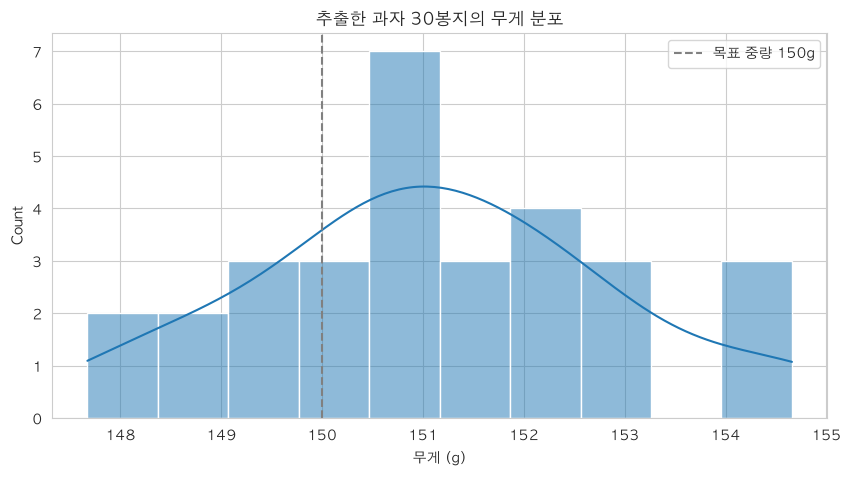

In [8]:
# [문제 2] 과자 한 봉지 중량 — 데이터 생성 (30봉지 무게 측정값)
np.random.seed(42)
sample_weights = np.random.normal(loc=151.5, scale=2, size=30)   # 측정된 30개 무게
pop_mean = 150                                                    # 목표 중량 (모평균 μ0)

print(f"표본 평균: {sample_weights.mean():.2f} g")
print(f"표본 표준편차: {sample_weights.std(ddof=1):.2f} g")

# 분포 시각화
sns.histplot(sample_weights, bins=10, kde=True)
plt.axvline(pop_mean, color="gray", linestyle="--", label="목표 중량 150g")
plt.title("추출한 과자 30봉지의 무게 분포")
plt.xlabel("무게 (g)")
plt.legend()
plt.show()

In [9]:
# [문제 2] Q1. 가설 세우기 (주석으로 작성)
# H0 (귀무가설): 모평균 μ = 150g  (목표 중량을 잘 맞추고 있다)
# H1 (대립가설): 모평균 μ ≠ 150g  (목표 중량에서 벗어났다) → 양측검정

In [10]:
# [문제 2] Q2·Q3. 일표본 t-검정 및 유의수준 0.05로 결론
alpha = 0.05
t_stat, p_val = stats.ttest_1samp(sample_weights, popmean=pop_mean)   # 양측검정 기본값

print(f"t-통계량 = {t_stat:.3f}")
print(f"p-value (양측) = {p_val:.4f}")

if p_val < alpha:
    print(f"p({p_val:.4f}) < α({alpha}) → H0 기각: 평균 중량이 150g과 다르다")
else:
    print(f"p({p_val:.4f}) ≥ α({alpha}) → H0 기각 못함: 150g과 다르다는 근거 부족")

t-통계량 = 3.419
p-value (양측) = 0.0019
p(0.0019) < α(0.05) → H0 기각: 평균 중량이 150g과 다르다


In [11]:
# [문제 2] Q4. H0(평균 = 150g)가 참이라고 가정하고, 30개짜리 표본 평균을 10,000번 생성
np.random.seed(42)
s_obs = sample_weights.std(ddof=1)            # 우리가 가진 표본의 표준편차를 사용
sim_means = np.empty(10_000)                  # 표본 평균을 담을 배열
for i in range(10_000):
    # H0 세계: 평균 150, 표준편차 s_obs인 정규분포에서 30개 뽑고 평균 계산
    sim_means[i] = np.random.normal(loc=pop_mean, scale=s_obs, size=30).mean()

print(f"시뮬레이션 평균들의 평균: {sim_means.mean():.2f}")
print(f"시뮬레이션 평균들의 표준편차: {sim_means.std(ddof=1):.3f}")

시뮬레이션 평균들의 평균: 150.00
시뮬레이션 평균들의 표준편차: 0.332


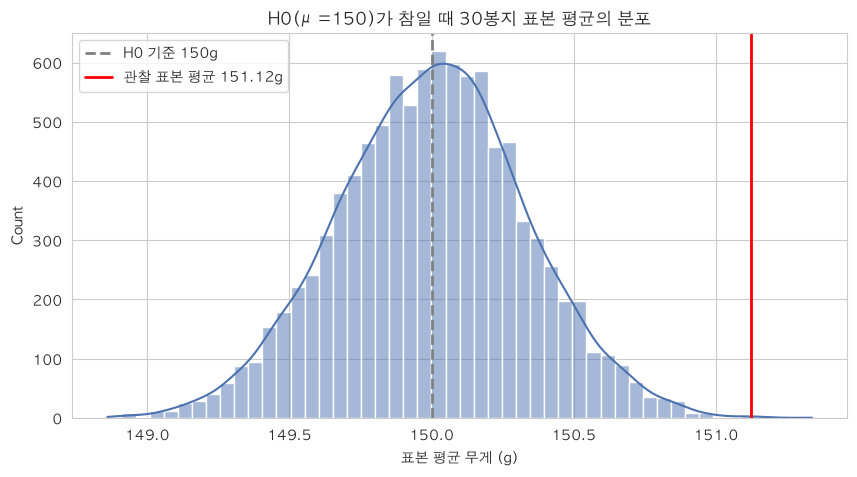

시뮬레이션 양측 p-value ≈ 0.0006  (t-검정 p-value = 0.0019)


In [12]:
# [문제 2] Q5. 시뮬레이션 표본 평균 분포 + 관찰된 표본 평균 세로선
obs_mean = sample_weights.mean()

plt.figure(figsize=(10, 5))
sns.histplot(sim_means, bins=50, kde=True, color="#4C72B0")
plt.axvline(pop_mean, color="gray", linestyle="--", linewidth=2, label="H0 기준 150g")
plt.axvline(obs_mean, color="red", linestyle="-", linewidth=2, label=f"관찰 표본 평균 {obs_mean:.2f}g")
plt.title("H0(μ=150)가 참일 때 30봉지 표본 평균의 분포")
plt.xlabel("표본 평균 무게 (g)")
plt.legend()
plt.show()

# 시뮬레이션 기반 양측 p-value: 기준에서 관찰값만큼 떨어진 평균이 나오는 비율
dist = abs(sim_means - pop_mean)
sim_p2 = np.mean(dist >= abs(obs_mean - pop_mean))
print(f"시뮬레이션 양측 p-value ≈ {sim_p2:.4f}  (t-검정 p-value = {p_val:.4f})")

### 📝 해설

**결론: 평균 중량은 150g과 다르다. (p = 0.002, 관찰 평균 151.12g)**

- 표본 평균이 목표보다 약 1.1g 무겁고, 이 차이는 우연으로 보기 어렵다.
- 시뮬레이션 분포는 150 근처에 모이며(표준편차 약 0.33), 관찰값 151.12는 오른쪽 끝 영역에 있다.
- 시뮬레이션 p-값(0.0006)과 t-검정 p-값(0.0019)은 같은 방향의 결론이다. 차이는 시뮬레이션이 표준편차를 고정해 쓰는 근사 때문이다.

**현장 조치:** 목표보다 무거운 것은 원가 손실이므로, 충전·계량 설비의 설정값을 점검하고 목표 중량을 150g으로 맞추는 것이 합리적이다.


### 🧠 데이터를 어떻게 읽을까요?

**1. Q5 히스토그램은 어떤 분포이고, 왜 정규분포처럼 보일까?**
→ **H₀(평균 150)가 참일 때, 30봉지 표본 평균이 얻어지는 분포**다. 개별 봉지 무게는 제각각이어도, 30개를 평균 내면 값들이 서로 상쇄되어 **중심극한정리**에 따라 종 모양이 된다.

**2. 관찰된 표본 평균(151.12g)은 흔한 값인가?**
→ **흔하지 않다.** 150에서 약 1.1g 떨어져 있는데, 이 분포에서 표준편차(약 0.33g)의 3배 이상 떨어진 극단적인 위치다. 그래서 p-값(0.002)이 작게 나온다. 세로선이 분포 꼬리에 있을수록 p-값은 작아진다.

**3. p-값이 0.001이었다면 세로선은 어디쯤일까?**
→ **분포의 더 바깥쪽 끝**이다. p-값이 작을수록 관찰값은 H₀ 분포의 꼬리 깊숙이 있다. 즉 "평균 150"이라는 가정이 더 설득력을 잃는다는 뜻이다.

**4. 목표보다 무겁게 나오는 것은 공장에 어떤 손실인가? 조치는?**
→ **원가 손실**이다. 과자 1봉지당 1g이 더 들어가면 생산량 전체로는 원재료비가 계속 새어 나간다. 반대로 가벼우면 법정 표시량 위반 위험이 있다. 따라서 목표 중량을 150g으로 맞추도록 **충전 설비 설정과 계량기를 점검**하고, 공정 평균을 150g 근처로 재조정한 뒤 다시 표본 검정을 하는 것이 합리적이다.

---

**📚 이 문제에서 나온 개념 정리**

- **표준오차(SE, Standard Error):** 표본 평균의 흔들림 크기. SE = s ÷ √n. 표본 표준편차(개별 값의 흩어짐)와 다르다.
- **중심극한정리(CLT):** 표본 크기가 충분하면(보통 n ≥ 30) 원래 분포 모양과 관계없이 표본 평균의 분포가 정규분포에 가까워진다.
- **t-분포:** σ를 모를 때 표본 표준편차로 추정하므로 생기는 추가 흔들림을 반영한 분포. 꼬리가 정규분포보다 두껍고, 자유도(df = n − 1)가 커질수록 정규분포에 가까워진다.
- **검정통계량 t:** (표본 평균 − 기준값) ÷ 표준오차. 기준에서 표준오차 몇 개만큼 떨어졌는지를 나타낸다.
- **신뢰구간(CI, Confidence Interval):** 표본 평균 ± t × SE. 예를 들어 95% 신뢰구간이 150을 포함하지 않으면, 같은 가설검정은 p < 0.05와 같은 결론을 낸다.


---
## 문제 3. 어떤 온라인 학습 방식이 더 효과적일까?

### 📖 개념
- **이표본 t-검정:** 서로 독립인 두 집단의 평균 차이를 검정
- **가정 1 – 정규성 (Shapiro-Wilk):** H₀는 "정규분포를 따른다". p ≥ 0.05면 정규 가정을 의심하지 않는다
- **가정 2 – 등분산 (Levene):** H₀는 "두 집단의 분산이 같다". p < 0.05면 등분산을 의심하고 **Welch 검정**(`equal_var=False`)을 쓴다
- **순열검정(Permutation test):** 두 집단을 합쳐 무작위로 다시 나누며, "효과가 없을 때"의 차이 분포를 직접 만든다


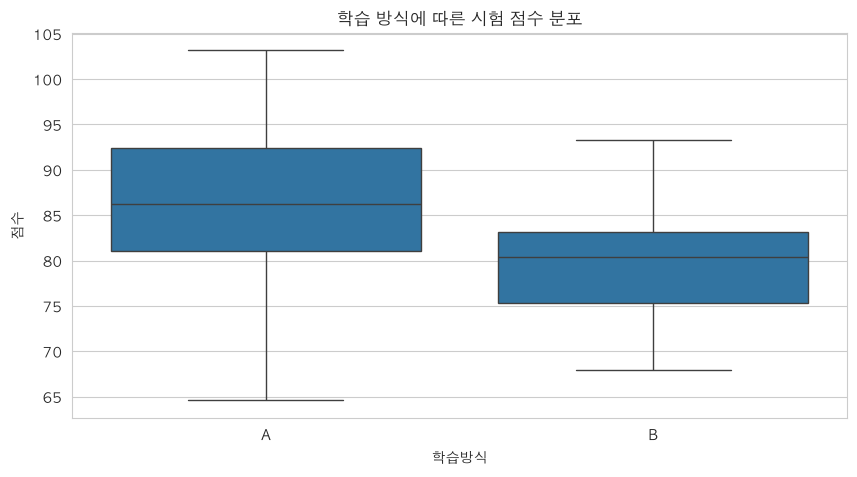

In [14]:
# [문제 3] 학습 방식 A vs B — 데이터 생성 (시험 점수)
np.random.seed(0)
group_a_scores = np.random.normal(loc=85, scale=8, size=50)   # A 방식 50명
group_b_scores = np.random.normal(loc=80, scale=7, size=50)   # B 방식 50명

df_scores = pd.DataFrame({
    "점수": np.concatenate([group_a_scores, group_b_scores]),
    "학습방식": ["A"] * 50 + ["B"] * 50,
})

# 두 그룹의 점수 분포 시각화
sns.boxplot(x="학습방식", y="점수", data=df_scores)
plt.title("학습 방식에 따른 시험 점수 분포")
plt.show()

In [16]:
# [문제 3] Q1. 정규성 검정 (Shapiro-Wilk)
# H0: 데이터는 정규분포를 따른다.
for name, g in [("A", group_a_scores), ("B", group_b_scores)]:
    w, p = stats.shapiro(g)                       # 검정통계량 W와 p-value 반환
    verdict = "정규성 기각 못함(정규 가정 OK)" if p >= 0.05 else "정규성 의심"
    print(f"그룹 {name}: W = {w:.3f}, p = {p:.3f} → {verdict}")
    # W값이 1에 가까울수록 정규에 가깝다. p-value가 0.05 이상이면 정규성 가정 OK, 0.05 미만이면 정규성 의심


그룹 A: W = 0.988, p = 0.877 → 정규성 기각 못함(정규 가정 OK)
그룹 B: W = 0.987, p = 0.837 → 정규성 기각 못함(정규 가정 OK)


In [ ]:
# [문제 3] Q2. 등분산성 검정 (Levene)
# H0: 두 그룹의 분산은 같다.
lev_stat, lev_p = stats.levene(group_a_scores, group_b_scores)
print(f"Levene: W = {lev_stat:.3f}, p = {lev_p:.3f}")
print("→ 등분산 가정 OK" if lev_p >= 0.05 else "→ 등분산 의심: equal_var=False(Welch) 사용")
# W값이 0에 가까울수록 분산이 비슷하고 클수록 분산 차이가 크다. p-value가 0.05 이상이면 등분산 가정 OK, 0.05 미만이면 등분산 의심

Levene: W = 6.133, p = 0.015
→ 등분산 의심: equal_var=False(Welch) 사용


In [ ]:
# [문제 3] Q3. 이표본 t-검정
# H0: 두 그룹의 평균은 같다.  /  H1: 두 그룹의 평균은 다르다.
# Levene 결과(p ≥ 0.05)에 따라 등분산 가정을 설정합니다.
equal_var_flag = lev_p >= 0.05                    # 등분산을 기각하지 못하면 True
t_two, p_two = stats.ttest_ind(group_a_scores, group_b_scores, equal_var=equal_var_flag)

print(f"equal_var = {equal_var_flag}")
print(f"t-통계량 = {t_two:.3f}, p-value = {p_two:.4f}")
print(f"A 평균 - B 평균 = {group_a_scores.mean() - group_b_scores.mean():.2f}점")

equal_var = False
t-통계량 = 4.043, p-value = 0.0001
A 평균 - B 평균 = 6.27점


In [21]:
# [문제 3] Q4. H0(두 방식 효과 같음)를 가정한 순열 시뮬레이션 10,000번
np.random.seed(0)
all_scores = np.concatenate([group_a_scores, group_b_scores])   # 100명 점수를 한 덩어리로
n_a = len(group_a_scores)                                       # A 그룹 크기 50
obs_diff = group_a_scores.mean() - group_b_scores.mean()        # 실제 관찰된 평균 차이

perm_diffs = np.empty(10_000)
for i in range(10_000):
    shuffled = np.random.permutation(all_scores)                # 100명을 무작위로 섞기
    fake_a, fake_b = shuffled[:n_a], shuffled[n_a:]             # 앞 50명 = 가짜 A, 나머지 = 가짜 B
    perm_diffs[i] = fake_a.mean() - fake_b.mean()               # 가짜 평균 차이 저장

# 양측 p-value: 관찰된 차이만큼 극단적인 차이가 나온 비율
perm_p = np.mean(np.abs(perm_diffs) >= abs(obs_diff))
print(f"관찰된 평균 차이 = {obs_diff:.2f}점")
print(f"순열검정 p-value ≈ {perm_p:.4f}")

관찰된 평균 차이 = 6.27점
순열검정 p-value ≈ 0.0001


/opt/anaconda3/envs/myenv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) AppleGothic.
  fig.canvas.print_figure(bytes_io, **kw)


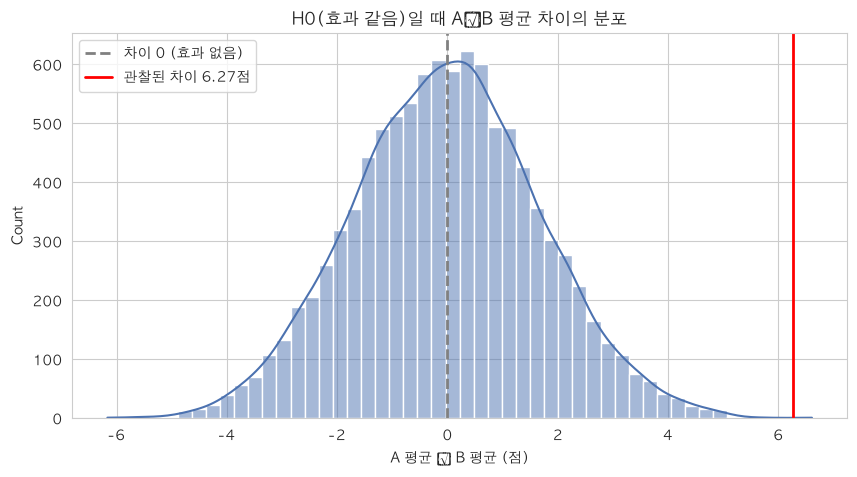

In [22]:
# [문제 3] Q5. 평균 차이 분포 + 관찰된 차이 세로선
plt.figure(figsize=(10, 5))
sns.histplot(perm_diffs, bins=50, kde=True, color="#4C72B0")
plt.axvline(0, color="gray", linestyle="--", linewidth=2, label="차이 0 (효과 없음)")
plt.axvline(obs_diff, color="red", linewidth=2, label=f"관찰된 차이 {obs_diff:.2f}점")
plt.title("H0(효과 같음)일 때 A−B 평균 차이의 분포")
plt.xlabel("A 평균 − B 평균 (점)")
plt.legend()
plt.show()

### 📝 해설

**결론: 방식 A가 방식 B보다 평균 점수가 유의하게 높다. (차이 6.27점, p = 0.0001)**

- **정규성:** 두 그룹 모두 p > 0.05 → 정규 가정에 문제 없음
- **등분산:** Levene p = 0.015 < 0.05 → 분산이 다르므로 **Welch 검정** 사용
- **t-검정 결과:** t = 4.04, p = 0.0001 → 평균 차이는 우연으로 보기 어렵다
- **순열검정:** 효과가 없다고 가정해 섞었을 때 6.27점 이상 차이가 날 확률은 약 0.01% → 같은 결론
- 히스토그램의 중심이 0 근처인 이유: H₀(효과 없음)에서는 A와 B를 나누는 방식과 무관하게 차이의 기대값이 0이기 때문이다. 관찰된 차이(6.27)는 이 분포의 바깥에 있다.

**활용:** 방식 A를 우선 채택하고, 효과 크기(6점 차이)를 기준으로 학습 콘텐츠 설계에 반영한다.


### 🧠 데이터를 어떻게 읽을까요?

**1. 정규성·등분산 검정의 p-값은 각각 어떻게 해석하나? t-검정에 문제는 없나?**
→ **정규성은 문제없고, 등분산은 가정이 깨졌다.** 정규성 p = 0.877, 0.837은 "정규분포라고 볼 근거가 충분하다"는 뜻이다(정규라는 증명은 아님). 등분산 p = 0.015는 "분산이 같다고 볼 수 없다"이므로 일반 t-검정 대신 **Welch 검정**을 써야 한다. 그래서 t-검정 자체는 문제없이 수행할 수 있다.

**2. Q5 히스토그램 중심이 0 근처인 이유는?**
→ **H₀(효과 없음)에서는 A와 B의 평균 차이가 0을 중심으로 흩어지기 때문이다.** 순열검정은 두 집단을 섞어 무작위로 나누므로 "방식에 따른 차이"가 사라진 세계를 만든다. 이 세계에서 차이의 기댓값은 0이다.

**3. 관찰된 차이(6.27점)는 우연의 범위 안인가, 밖인가?**
→ **밖이다.** 히스토그램에서 빨간 세로선은 0에서 한참 떨어진 오른쪽 끝에 있다. 효과가 없다면 이만큼 차이 날 확률은 약 0.01%다.

**4. 시각적 판단과 Q3의 p-값은 어떤 관계인가?**
→ **같은 결론을 다른 방식으로 말한다.** 시각적으로 세로선이 분포 바깥에 있다는 것은, 바깥쪽 면적(p-값)이 0.05보다 훨씬 작다는 것과 같다. 그림은 "얼마나 극단적인가", p-값은 "그 극단성을 확률로 얼마나 표현하는가"다.

**5. 통계적으로 유의하다면 교육 기업은 어떻게 활용할까?**
→ **A 방식을 우선 도입하되, '유의하다'와 '얼마나 중요한가'를 구분해서 활용한다.** 평균 차이 6점은 실무적으로도 큰 차이지만, 실제 도입 전에는 신뢰구간과 비용을 함께 봐야 한다. 또한 "한 달 학습, 한 번의 시험"이라는 조건에서 얻은 결과이므로, 장기 효과를 추가로 검증하는 것이 좋다.

---

**📚 이 문제에서 나온 개념 정리**

- **Shapiro-Wilk 검정:** H₀는 "정규분포를 따른다". 표본 크기가 작을 때 정규성을 확인하는 대표적 방법. p ≥ 0.05면 정규 가정을 기각하지 못한다.
- **Levene 검정:** H₀는 "두 집단의 분산이 같다". 평균이 아니라 분산(흩어짐)의 차이를 본다. p < 0.05면 등분산 가정을 버린다.
- **Welch t-검정:** 두 집단의 분산이 다를 때 쓰는 t-검정. 자유도를 자동으로 조정하므로, 분산이 같든 다르든 안전한 기본값이다.
- **순열검정(Permutation test):** 데이터를 섞어 "효과가 없는 세계"를 직접 만들고, 관찰된 차이가 그 안에서 얼마나 드문지 세는 방법. 정규성 같은 분포 가정이 필요 없다.
- **효과크기(Effect size):** p-값은 "차이가 있는가"를, 효과크기는 "차이가 얼마나 큰가"를 말한다. 평균 차이를 표준편차로 나눈 Cohen's d가 대표적이다. 표본이 커지면 p-값은 작아지지만 효과크기는 그대로이므로 둘을 함께 봐야 한다.


---
## 문제 4. 연령대별로 선호하는 영화 장르가 다를까?

### 📖 개념: 카이제곱 독립성 검정
- **언제 쓰나:** 두 범주형 변수가 서로 관련이 있는지 검정 (분할표)
- **기대 빈도:** 두 변수가 독립이라면 각 칸에 기대되는 빈도 = (행합 × 열합) ÷ 전체
- **검정통계량:** χ² = Σ (관측 − 기대)² ÷ 기대
- **자유도:** (행 수 − 1) × (열 수 − 1)
- **시뮬레이션 아이디어:** 독립이라는 가정에서 가상 설문을 반복해 χ²의 분포를 만든다


관측 빈도 (Observed Frequencies):
     액션  로맨스
20대  70   30
30대  50   60
40대  30   60


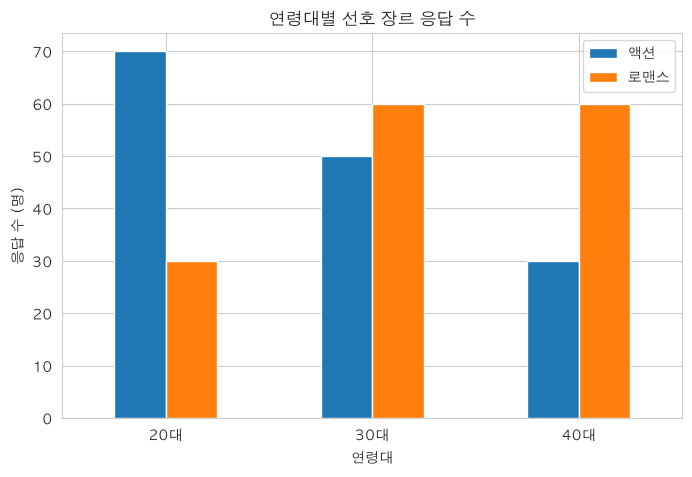

In [36]:
# [문제 4] 연령대 × 장르 분할표 (관측 빈도)
data = {"액션": [70, 50, 30],
        "로맨스": [30, 60, 60]}
observed = pd.DataFrame(data, index=["20대", "30대", "40대"])

print("관측 빈도 (Observed Frequencies):")
print(observed)

# 분할표 시각화
observed.plot(kind="bar", figsize=(8, 5))
plt.title("연령대별 선호 장르 응답 수")
plt.xlabel("연령대")
plt.ylabel("응답 수 (명)")
plt.xticks(rotation=0)
plt.show()

In [37]:
# [문제 4] Q1. 가설 세우기 (주석)
# H0 (귀무가설): 연령대와 선호 장르는 독립이다 (관련 없음)
# H1 (대립가설): 연령대와 선호 장르는 독립이 아니다 (관련 있음)

In [38]:
# [문제 4] Q2. 카이제곱 독립성 검정
chi2, p_chi, dof, expected = stats.chi2_contingency(observed)

print(f"카이제곱 통계량 = {chi2:.3f}")
print(f"p-value        = {p_chi:.6f}")
print(f"자유도 df      = {dof}   (행-1) × (열-1) = (3-1)×(2-1)")

# 기대 빈도를 관측 빈도와 같은 모양의 표로 출력
expected_df = pd.DataFrame(expected, index=observed.index, columns=observed.columns).round(1)
print("\n기대 빈도 (Expected, H0가 참일 때):")
print(expected_df)

카이제곱 통계량 = 26.909
p-value        = 0.000001
자유도 df      = 2   (행-1) × (열-1) = (3-1)×(2-1)

기대 빈도 (Expected, H0가 참일 때):
       액션   로맨스
20대  50.0  50.0
30대  55.0  55.0
40대  45.0  45.0


In [33]:
# [문제 4] Q3. H0(독립)을 가정한 가상 설문 5,000번 시뮬레이션
np.random.seed(7)
N = 300                                              # 응답자 수 (실제와 동일)

# 독립이라는 가정 하에서 쓸 확률: 연령대 비율, 장르 비율을 따로 계산
p_age   = observed.sum(axis=1) / observed.values.sum()   # 20대·30대·40대 비율
p_genre = observed.sum(axis=0) / observed.values.sum()   # 액션·로맨스 비율

sim_chi2 = np.empty(5_000)
for i in range(5_000):
    # 연령대와 장르를 서로 영향 없이 각각 뽑아 300명 생성
    ages   = np.random.choice(observed.index, size=N, p=p_age.values)
    genres = np.random.choice(observed.columns, size=N, p=p_genre.values)
    # 가상 분할표 만들고 카이제곱 통계량 계산
    sim_table = pd.crosstab(ages, genres)
    sim_chi2[i] = stats.chi2_contingency(sim_table)[0]

print(f"시뮬레이션 카이제곱 평균: {sim_chi2.mean():.3f}  (이론 기댓값 ≈ 자유도 {dof})")

시뮬레이션 카이제곱 평균: 2.011  (이론 기댓값 ≈ 자유도 2)


In [34]:
# [문제 4] Q3. H0(독립)을 가정한 가상 설문 5,000번 시뮬레이션 (빠른 버전)
np.random.seed(7)                                   # 재현성: 난수 고정
N = 300                                             # 응답자 수

# 1) 독립 가정 하의 확률 계산
p_age   = (observed.sum(axis=1) / observed.values.sum()).values   # 연령대 비율 (3개)
p_genre = (observed.sum(axis=0) / observed.values.sum()).values   # 장르 비율 (2개)

# 2) 독립이면 (연령, 장르) 6개 칸의 확률 = 연령 확률 × 장르 확률
joint_p = np.outer(p_age, p_genre).ravel()          # 6개 칸 확률 (합 = 1)

# 3) 300명을 6개 칸에 한 번에 배정 → 5,000개의 가상 분할표
#    결과 shape: (5000, 3, 2) = (반복, 연령대, 장르)
counts = np.random.multinomial(N, joint_p, size=5000).reshape(5000, 3, 2)

# 4) 각 가상 표의 기대 빈도 = (행합 × 열합) ÷ 전체 (카이제곱 공식 그대로)
row_tot  = counts.sum(axis=2, keepdims=True)        # 연령대별 합 (5000, 3, 1)
col_tot  = counts.sum(axis=1, keepdims=True)        # 장르별 합   (5000, 1, 2)
expected = row_tot * col_tot / N                    # 기대 빈도   (5000, 3, 2)

# 5) 카이제곱 통계량: Σ (관측 − 기대)² ÷ 기대, 칸별로 더함
sim_chi2 = ((counts - expected) ** 2 / expected).sum(axis=(1, 2))

print(f"시뮬레이션 카이제곱 평균: {sim_chi2.mean():.3f}  (이론 기댓값 ≈ 자유도 {dof})")

시뮬레이션 카이제곱 평균: 2.014  (이론 기댓값 ≈ 자유도 2)


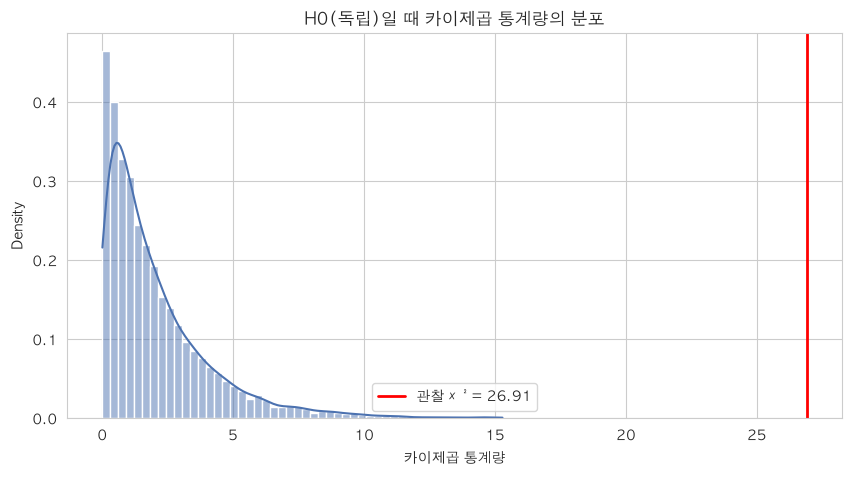

시뮬레이션 p-value ≈ 0.0000  (카이제곱 검정 p-value = 0.000001)


In [35]:
# [문제 4] Q4. 카이제곱 통계량 분포 + 관찰값 세로선
plt.figure(figsize=(10, 5))
sns.histplot(sim_chi2, bins=50, kde=True, color="#4C72B0", stat="density")
plt.axvline(chi2, color="red", linewidth=2, label=f"관찰 χ² = {chi2:.2f}")
plt.title("H0(독립)일 때 카이제곱 통계량의 분포")
plt.xlabel("카이제곱 통계량")
plt.legend()
plt.show()

sim_p4 = np.mean(sim_chi2 >= chi2)                   # 관찰값 이상이 나올 비율
print(f"시뮬레이션 p-value ≈ {sim_p4:.4f}  (카이제곱 검정 p-value = {p_chi:.6f})")

### 📝 해설

**결론: 연령대와 선호 장르는 독립이 아니다, 즉 관련이 있다. (χ² = 26.91, df = 2, p ≈ 0.000001)**

- 기대 빈도는 모든 연령대에서 액션 50 : 로맨스 50 수준이었지만, 관측값은 20대 액션(70)과 40대 로맨스(60)에 쏠려 있다.
- 시뮬레이션 χ²의 평균은 약 2로, 자유도(2)와 같다. 독립일 때 χ²는 보통 2 근처다.
- 관찰된 χ² = 26.9는 이 분포에서 거의 나오지 않는 극단값이다.
- **주의:** 카이제곱 검정은 "관련이 있다"까지만 말한다. 어느 칸이 얼마나 차이 나는지는 칸별 잔차로 따로 확인해야 한다.

**활용:** 20대는 액션 편성·신작 심야 상영을, 40대는 로맨스 장르의 주말 상영과 할인 이벤트를 강화하는 전략이 근거를 가진다.


### 🧠 데이터를 어떻게 읽을까요?

**1. 기대 빈도는 무슨 의미이고, 관측과의 차이가 클수록 χ²는 어떻게 변할까?**
→ **기대 빈도는 "연령과 장르가 아무 관계없다면 각 칸에 있어야 할 인원"이다.** 관측과 기대의 차이가 클수록 χ²는 커진다. 제곱을 하므로 차이가 큰 칸이 값을 크게 끌어올린다.

칸별로 보면 기여도가 보인다(표준화 잔차 = (관측 − 기대) ÷ √기대):
- 20대 액션: (70 − 50) ÷ √50 ≈ **+2.83**, 20대 로맨스: **−2.83**
- 40대 액션: **−2.24**, 40대 로맨스: **+2.24**
- 30대: ±0.67로 거의 차이 없음

이 네 칸이 χ²의 대부분을 만든다.

**2. Q4 히스토그램은 무엇이고, 관찰된 χ²(26.9)는 흔한가?**
→ **연령과 장르가 독립일 때 χ² 값의 분포**다. 평균은 자유도 2 근처다. 관찰값 26.9는 그 분포에서 거의 나오지 않는 극단값이다.

**3. 0.05 수준에서 "연관성이 있다"고 결론 내릴 수 있나?**
→ **그렇다.** p ≈ 0.000001로 0.05보다 훨씬 작다. 다만 "어떤 연령대가 어떤 장르를 얼마나 좋아하는가"까지 말해 주지는 않으므로, 잔차를 보고 해석을 덧붙여야 한다.

표준화 잔차 = (관측 − 기대) ÷ √기대

| 칸 | 관측 | 기대 | 잔차 | 해석 |
|---|---|---|---|---|
| 20대 · 액션 | 70 | 50 | **+2.83** | 기대보다 많이 선택 |
| 20대 · 로맨스 | 30 | 50 | **−2.83** | 기대보다 적게 선택 |
| 30대 · 액션 | 50 | 55 | −0.67 | 차이 작음 |
| 30대 · 로맨스 | 60 | 55 | +0.67 | 차이 작음 |
| 40대 · 액션 | 30 | 45 | **−2.24** | 기대보다 적게 선택 |
| 40대 · 로맨스 | 60 | 45 | **+2.24** | 기대보다 많이 선택 |

- **잔차의 절댓값이 2 이상**인 칸이 연관성을 주도한다. 여기서는 20대와 40대 칸이 해당한다.
- 양수는 "독립이었을 때보다 많음", 음수는 "독립이었을 때보다 적음"이다.
- 30대는 잔차가 0.7 이하라 연령과 장르의 연관에 거의 기여하지 않는다.
- 네 칸의 잔차 제곱을 합하면 약 26.9로, 전체 χ² 값과 일치한다. 즉 **χ²의 대부분은 20대와 40대 칸에서 나온다.**

**결론:** 20대는 액션을, 40대는 로맨스를 상대적으로 선호한다. 30대는 두 장르를 비슷하게 선호한다.

**4. 영화관은 연령대별로 어떤 전략을 세울 수 있나?**
→ **타깃별 편성과 프로모션을 나눈다.**
- 20대: 액션 신작 편성 확대, 심야 상영 중심
- 40대: 로맨스 장르의 주말 상영, 시니어·커플 할인
- 30대: 장르 편차가 작으므로 특정 장르 편중보다 **상영 시간대**나 **가격 혜택**으로 공략

---

**📚 이 문제에서 나온 개념 정리**

- **분할표(Contingency table):** 두 범주형 변수의 교차 빈도표. 행은 연령대, 열은 장르.
- **독립(Independence):** 한 변수의 값을 알아도 다른 변수 분포가 달라지지 않는 상태. 독립이면 분할표의 각 행 비율이 모두 같아야 한다.
- **기대 빈도(Expected frequency):** E = (행합 × 열합) ÷ 전체. 독립이라는 가정에서 각 칸에 기대되는 값.
- **카이제곱 통계량:** χ² = Σ(관측 − 기대)² ÷ 기대. 모든 칸의 불일치를 합친 값이며, 0에 가까우면 독립에 가깝다.
- **자유도:** (행 − 1) × (열 − 1). 여기서는 (3 − 1) × (2 − 1) = 2. 자유도가 χ² 분포의 모양을 정한다.
- **잔차(Residual):** 칸별 관측과 기대의 차이를 표준화한 값. 어떤 칸이 연관성을 만드는지 찾는 도구다.
- **카이제곱 검정의 주의:** 기대 빈도가 대부분 5 이상이어야 근사가 믿을 만하다. 이 데이터는 모든 칸이 45 이상이라 문제없다.


---
## 문제 5. 미니 프로젝트: 어떤 신규 비료가 가장 효과적일까?

### 📖 개념
- **일원분산분석(One-way ANOVA):** 세 집단 이상의 평균이 모두 같은지 한 번에 검정
  - H₀: μ_A = μ_B = μ_C / H₁: 적어도 하나는 다르다
  - F = 집단 사이 변동 ÷ 집단 내부 변동. F가 클수록 집단 차이가 크다
- **사후분석(Tukey HSD):** ANOVA가 유의할 때 어느 쌍이 다른지 확인. 여러 번 비교해도 1종 오류가 커지지 않도록 보정한다
- **왜 t-검정을 여러 번 하면 안 되나:** 쌍별 검정을 3번 하면 1종 오류가 누적된다(다중비교 문제)


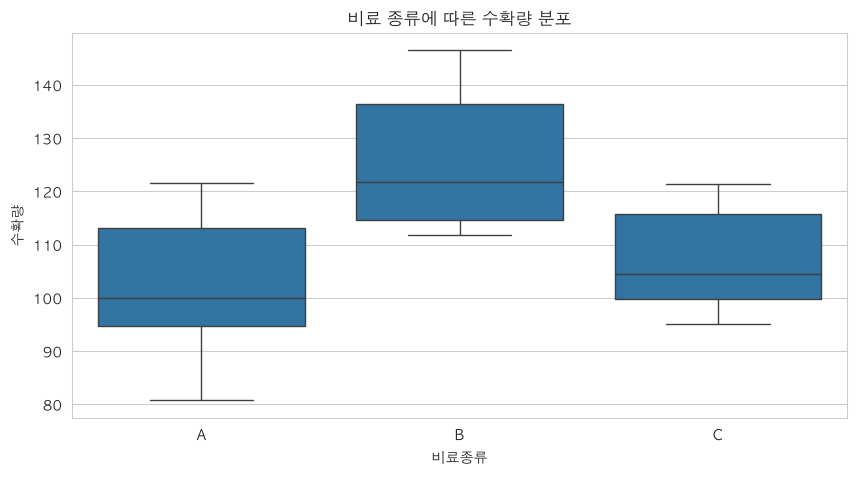

        mean    std  count
비료종류                      
A     102.30  13.03     10
B     125.98  13.75     10
C     107.15   9.74     10


In [ ]:
# [문제 5] 신규 비료 3종 — 데이터 생성 (각 10개 밭)
np.random.seed(123)
fertilizer_a = np.random.normal(loc=105, scale=10, size=10)
fertilizer_b = np.random.normal(loc=120, scale=12, size=10)
fertilizer_c = np.random.normal(loc=108, scale=9,  size=10)

# 데이터프레임으로 변환 (사후분석을 위해)
df = pd.DataFrame({
    "수확량": np.concatenate([fertilizer_a, fertilizer_b, fertilizer_c]),
    "비료종류": ["A"] * 10 + ["B"] * 10 + ["C"] * 10,
})

# 데이터 탐색 시각화
sns.boxplot(x="비료종류", y="수확량", data=df)
plt.title("비료 종류에 따른 수확량 분포")
plt.show()

print(df.groupby("비료종류")["수확량"].agg(["mean", "std", "count"]).round(2))

In [40]:
# [문제 5] Q1. 일원분산분석(ANOVA)
# H0: 세 비료의 평균 수확량은 모두 같다.
# H1: 적어도 하나 이상의 비료 평균 수확량은 다르다.
f_stat, p_anova = stats.f_oneway(fertilizer_a, fertilizer_b, fertilizer_c)
print(f"F-통계량 = {f_stat:.3f}")
print(f"p-value  = {p_anova:.6f}")

F-통계량 = 10.346
p-value  = 0.000462


In [41]:
# [문제 5] Q2. ANOVA가 유의할 때만 Tukey's HSD 사후분석
alpha = 0.05
if p_anova < alpha:
    tukey = pairwise_tukeyhsd(endog=df["수확량"], groups=df["비료종류"], alpha=alpha)
    print(tukey)
else:
    print("ANOVA 유의하지 않음 → 사후분석 생략")

 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
     A      B  23.6754 0.0006  10.0402 37.3106   True
     A      C   4.8429 0.6569  -8.7923 18.4781  False
     B      C -18.8325 0.0054 -32.4677 -5.1972   True
-----------------------------------------------------


In [43]:
# [문제 5] Q3. H0(세 비료 평균 동일)를 가정한 시뮬레이션 5,000번
np.random.seed(2024)
grand_mean = df["수확량"].mean()        # 전체 평균 (H0 하의 공통 평균)
grand_sd   = df["수확량"].std(ddof=1)   # 전체 표준편차 (H0 하의 공통 표준편차)

sim_F = np.empty(5_000)
for i in range(5_000):
    # 세 비료가 같다고 가정: 같은 분포에서 10개씩 3그룹 생성
    g1 = np.random.normal(grand_mean, grand_sd, 10)
    g2 = np.random.normal(grand_mean, grand_sd, 10)
    g3 = np.random.normal(grand_mean, grand_sd, 10)
    sim_F[i] = stats.f_oneway(g1, g2, g3).statistic

print(f"시뮬레이션 F 평균: {sim_F.mean():.3f}  (이론 기댓값 ≈ df2/(df2-2) ≈ 1.1)")

시뮬레이션 F 평균: 1.081  (이론 기댓값 ≈ df2/(df2-2) ≈ 1.1)


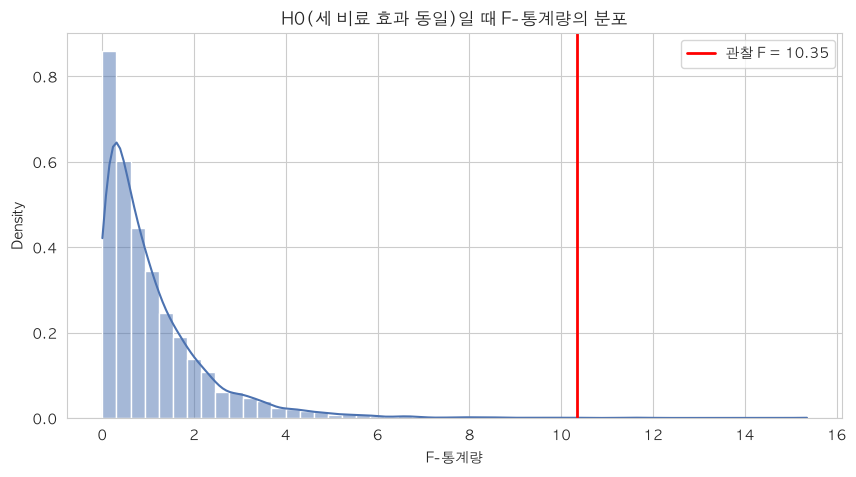

시뮬레이션 p-value ≈ 0.0006  (ANOVA p-value = 0.000462)


In [44]:
# [문제 5] Q4. F-통계량 분포 + 관찰값 세로선
plt.figure(figsize=(10, 5))
sns.histplot(sim_F, bins=50, kde=True, color="#4C72B0", stat="density")
plt.axvline(f_stat, color="red", linewidth=2, label=f"관찰 F = {f_stat:.2f}")
plt.title("H0(세 비료 효과 동일)일 때 F-통계량의 분포")
plt.xlabel("F-통계량")
plt.legend()
plt.show()

sim_p5 = np.mean(sim_F >= f_stat)
print(f"시뮬레이션 p-value ≈ {sim_p5:.4f}  (ANOVA p-value = {p_anova:.6f})")

### 📝 해설

**결론: 세 비료의 효과는 같지 않다. 비료 B가 가장 효과적이다.**

- **ANOVA:** F = 10.35, p = 0.00046 → 적어도 하나는 다르다
- **Tukey 사후분석** (표의 meandiff는 두 번째 집단 − 첫 번째 집단):
  - **B − A = +23.7 (p = 0.0006, reject = True)** → B가 A보다 유의하게 높다
  - **B − C = +18.8 (p = 0.005, reject = True)** → B가 C보다 유의하게 높다
  - **C − A = +4.8 (p = 0.66, reject = False)** → A와 C는 차이 없음
- 시뮬레이션 F의 평균은 약 1.1로 이론 기댓값과 맞고, 관찰값 10.35는 분포 바깥의 극단값이다.

**추천:** 비료 B. A·C와 비교해 수확량 차이가 통계적으로 유의하다.

**한계와 보완:**
- 그룹당 표본이 10개로 작아 검정력이 낮다. 차이가 있어도 놓칠 수 있는 구조다.
- 신뢰구간(lower, upper)이 0을 포함하지 않는 쌍(A–B, B–C)만 차이가 확실하다고 볼 수 있다. (C_A 구간이 0을 포함함 -> 방향도 크기도 확정할 수 없음 -> "차이가 없다"가 아니라 "차이를 확인할 근거가 부족하다"로 해석
- 비용 대비 효과와 토양 조건의 반복성까지 확인하려면 밭 수를 늘린 추가 실험이 필요하다.


### 🧠 데이터를 어떻게 읽을까요?

**1. ANOVA의 p-값으로 어떤 결론을 낼 수 있나? "모두 같다"인가 "적어도 하나는 다르다"인가?**
→ **"적어도 하나는 다르다"는 뜻이다.** p = 0.00046 < 0.05이므로 H₀(세 평균이 같다)를 기각한다. 하지만 **어느 비료가 다른지는 말해 주지 않는다.** 그래서 Tukey 사후분석이 필요하다.

**2. Tukey 결과표에서 reject가 True인 조합은 무엇을 뜻하나?**
→ **그 두 비료의 평균 차이가 다중비교 보정 후에도 유의하다**는 뜻이다.
- **B vs A: True** → B가 A보다 유의하게 수확량이 많다.
- **B vs C: True** → B가 C보다 유의하게 수확량이 많다.
- **A vs C: False** → A와 C는 차이가 확인되지 않았다.

**3. meandiff와 신뢰구간(lower, upper)은 무엇을 알려 주나? 0을 포함하면?**
→ **meandiff는 평균 차이의 추정치, 신뢰구간은 그 차이가 놓일 범위다.**
- B − A = **+23.7**, 구간 **[10.0, 37.3]** → 0을 포함하지 않으므로 차이가 확실하다.
- B − C = **+18.8**, 구간 **[5.2, 32.5]** → 0을 포함하지 않으므로 차이가 확실하다.
- C − A = **+4.8**, 구간 **[−8.8, 18.5]** → 0을 포함하므로 **방향도 크기도 확정할 수 없다.**

신뢰구간이 0을 포함하면 "차이가 없다"가 아니라 "**차이를 확인할 근거가 부족하다**"로 읽는다.

**4. 그룹당 10개라는 표본 크기는 결론에 어떤 영향을 줄까? 개선 방법은?**
→ **검정력이 낮아 차이가 있어도 놓칠 수 있고, 추정이 불안정해 신뢰구간이 넓다.** 특히 C와 A처럼 실제 차이가 작은 쌍은 10개로는 구분하기 어렵다.
- **개선 1:** 그룹당 표본을 늘린다. 차이를 더 정밀하게 잡을 수 있다.
- **개선 2:** 밭의 토양 조건을 블록으로 묶어 배치한다. 집단 내 흩어짐이 줄면 같은 표본으로도 검정력이 올라간다.
- **개선 3:** 실험을 여러 시즌·여러 지역에서 반복해 결과의 재현성을 확인한다.

**5. 추천은 무엇인가?**
→ **비료 B.** A와 C 모두보다 수확량이 유의하게 높다. 다만 표본이 작으므로 추천은 "현재 근거에서 가장 유력한 선택"이며, 확대 실험으로 확인하는 것을 조건으로 한다.

---

**📚 이 문제에서 나온 개념 정리**

- **일원분산분석(One-way ANOVA):** 세 집단 이상의 평균을 한 번에 비교한다. 집단 사이의 변동을 집단 내 변동으로 나눈 **F-통계량**으로 판단한다. F가 1에 가까우면 집단 차이가 흔들림 수준이고, 클수록 차이가 크다.
- **F-분포:** 두 분산의 비율이 따르는 분포. 자유도가 두 개(집단 간 k − 1, 집단 내 N − k)로 정해진다.
- **다중비교 문제(Multiple comparison problem):** 여러 쌍을 각각 t-검정하면 1종 오류가 누적된다. 3쌍에서 각각 α = 0.05를 쓰면 적어도 하나가 잘못 유의할 확률이 약 14%까지 올라간다.
- **Tukey HSD(Honestly Significant Difference):** 모든 쌍별 비교를 하면서도 전체 1종 오류를 α로 맞춰 주는 사후분석. 결과표의 meandiff, 보정된 p-adj, 신뢰구간, reject 열로 읽는다.
- **신뢰구간과 유의성의 관계:** 신뢰구간이 0을 포함하지 않으면 해당 쌍은 유의수준 α에서 차이가 있다고 판단된다. 두 방법은 같은 결론을 준다.
신뢰구간이 0을 포함하지 않으면 그 쌍의 차이는 우연으로 보기 어렵고, 0을 포함하면 차이와 방향과 크기를 확정할 수 없다.
- **검정력(Power):** 실제 차이가 있을 때 이를 찾아낼 확률. 1 − 2종 오류율. 표본이 작을수록 낮아진다.
